In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import matplotlib.pyplot as plt
from src.config import Config
from src.utils.seed import set_seed
from src.utils.io_helpers import save_checkpoint, save_json
from src.dataset import get_dataloaders
from src.models.vae import VariationalAutoencoder
from src.trainers.train_ae import train_vae
from src.evaluation.metrics import evaluate_ae_on_testset

set_seed(Config.SEED)
Config.ensure_dirs()
train_loader, val_loader, test_loader = get_dataloaders(batch_size=Config.BATCH_SIZE, seed=Config.SEED, num_workers=0)

vae = VariationalAutoencoder(
    input_dim=Config.INPUT_DIM,
    hidden_dim=256,
    latent_dim=Config.VAE_LATENT_DIM,
)

train_out = train_vae(
    model=vae,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=Config.VAE_EPOCHS,
    lr=Config.VAE_LR,
    kl_weight=Config.VAE_KL_WEIGHT,
    device=Config.DEVICE,
)

test_metrics, latency_ms = evaluate_ae_on_testset(vae, test_loader, Config.DEVICE, is_vae=True)
print(f"VAE Test Metrics: {test_metrics} | Latency (batch=64): {latency_ms} ms")

save_checkpoint(vae, Config.CHECKPOINT_DIR / "vae.pth")
save_json(
    {
        "model": "Variational Autoencoder (VAE)",
        "latent_dim": Config.VAE_LATENT_DIM,
        "kl_weight": Config.VAE_KL_WEIGHT,
        "avg_epoch_time_sec": train_out["avg_epoch_time_sec"],
        "inference_latency_ms_batch64": latency_ms,
        "test_metrics": test_metrics,
        "history": train_out["history"],
    },
    Config.METRICS_DIR / "vae_results.json",
)

[VAE] Epoch 01/30 | Train ELBO: 299.6132 (BCE: 284.8642, KLD: 14.7490) | Val MSE: 0.028799 | Time: 8.61s
[VAE] Epoch 05/30 | Train ELBO: 249.4506 (BCE: 234.5339, KLD: 14.9167) | Val MSE: 0.019252 | Time: 10.67s
[VAE] Epoch 10/30 | Train ELBO: 244.4734 (BCE: 229.0913, KLD: 15.3822) | Val MSE: 0.017123 | Time: 8.84s
[VAE] Epoch 15/30 | Train ELBO: 242.7520 (BCE: 226.9959, KLD: 15.7561) | Val MSE: 0.016372 | Time: 12.67s
[VAE] Epoch 20/30 | Train ELBO: 241.8322 (BCE: 225.9475, KLD: 15.8847) | Val MSE: 0.015977 | Time: 14.36s
[VAE] Epoch 25/30 | Train ELBO: 241.2975 (BCE: 225.3591, KLD: 15.9384) | Val MSE: 0.015856 | Time: 14.87s
[VAE] Epoch 30/30 | Train ELBO: 240.8899 (BCE: 224.9082, KLD: 15.9818) | Val MSE: 0.015411 | Time: 15.34s
VAE Test Metrics: {'mse': 0.015321, 'psnr': 18.147, 'ssim': 0.7416, 'latent_zero_ratio': 0.0008} | Latency (batch=64): 0.8303 ms


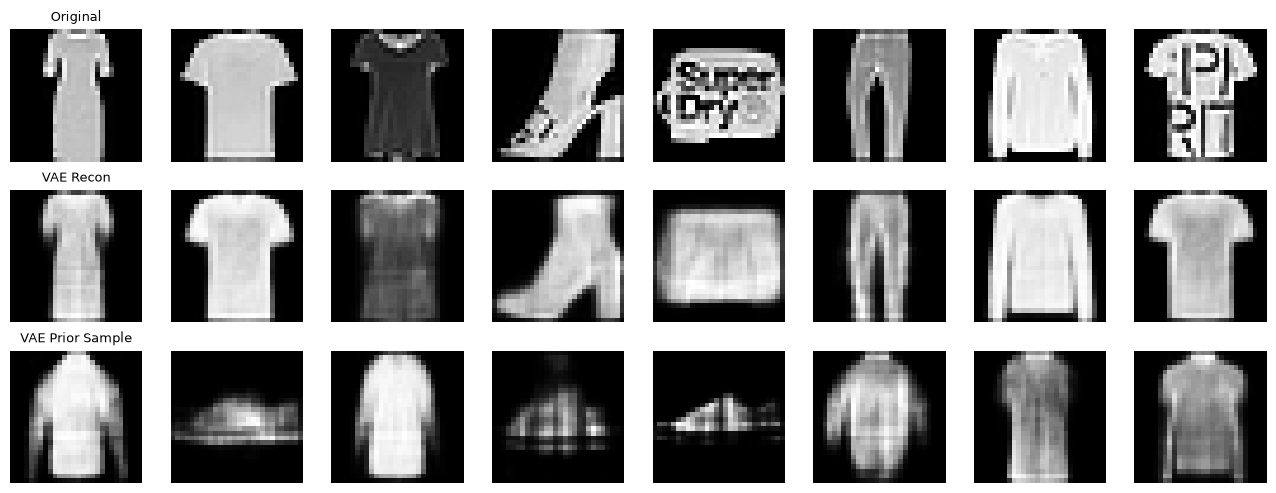

In [2]:
sample_x, _ = next(iter(test_loader))
sample_x = sample_x[:8].to(Config.DEVICE)
recon_x, _, _, _ = vae(sample_x)
gen_x = vae.sample(8, Config.DEVICE)

fig, axes = plt.subplots(3, 8, figsize=(13, 5))
for i in range(8):
    axes[0, i].imshow(sample_x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].imshow(recon_x[i].detach().cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")
    axes[2, i].imshow(gen_x[i].detach().cpu().squeeze(), cmap="gray")
    axes[2, i].axis("off")
axes[0, 0].set_title("Original", fontsize=9)
axes[1, 0].set_title("VAE Recon", fontsize=9)
axes[2, 0].set_title("VAE Prior Sample", fontsize=9)
plt.tight_layout()
plt.show()